About Dataset
- RowNumber—corresponds to the record (row) number and has no effect on the output.
- CustomerId—contains random values and has no effect on customer leaving the bank.
- Surname—the surname of a customer has no impact on their decision to leave the bank.
- CreditScore—can have an effect on customer churn, since a customer with a higher credit score is less likely to leave the bank.
- Geography—a customer’s location can affect their decision to leave the bank.
- Gender—it’s interesting to explore whether gender plays a role in a customer leaving the bank.
- Age—this is certainly relevant, since older customers are less likely to leave their bank than younger ones.
- Tenure—refers to the number of years that the customer has been a client of the bank. Normally, older clients are more loyal and less likely to leave a bank.
- Balance—also a very good indicator of customer churn, as people with a higher balance in their accounts are less likely to leave the bank compared to those with lower balances.
- NumOfProducts—refers to the number of products that a customer has purchased through the bank.
- HasCrCard—denotes whether or not a customer has a credit card. This column is also relevant, since people with a credit card are less likely to leave the bank.
- IsActiveMember—active customers are less likely to leave the bank.
- EstimatedSalary—as with balance, people with lower salaries are more likely to leave the bank compared to those with higher salaries.
- Exited—whether or not the customer left the bank.
- Complain—customer has complaint or not.
- Satisfaction Score—Score provided by the customer for their complaint resolution.
- Card Type—type of card hold by the customer.
- Points Earned—the points earned by the customer for using credit card.

### Все необходимые импорты

In [1]:
import kagglehub
from kagglehub import KaggleDatasetAdapter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, roc_auc_score, average_precision_score, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.inspection import DecisionBoundaryDisplay

### EDA

In [2]:
file_path = "Customer-Churn-Records.csv"

# Load the latest version
df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "radheshyamkollipara/bank-customer-churn",
  file_path,
)

Using Colab cache for faster access to the 'bank-customer-churn' dataset.


In [3]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425


In [4]:
df.drop(['Surname', 'RowNumber', 'CustomerId'], axis=1, inplace=True)

In [5]:
df = df.astype({'HasCrCard': bool, 'IsActiveMember': bool, 'Complain': bool})

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   CreditScore         10000 non-null  int64  
 1   Geography           10000 non-null  object 
 2   Gender              10000 non-null  object 
 3   Age                 10000 non-null  int64  
 4   Tenure              10000 non-null  int64  
 5   Balance             10000 non-null  float64
 6   NumOfProducts       10000 non-null  int64  
 7   HasCrCard           10000 non-null  bool   
 8   IsActiveMember      10000 non-null  bool   
 9   EstimatedSalary     10000 non-null  float64
 10  Exited              10000 non-null  int64  
 11  Complain            10000 non-null  bool   
 12  Satisfaction Score  10000 non-null  int64  
 13  Card Type           10000 non-null  object 
 14  Point Earned        10000 non-null  int64  
dtypes: bool(3), float64(2), int64(7), object(3)
memory usa

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
CreditScore,10000.0,650.528800,96.653299,350.00,584.00,652.000,718.0000,850.00
Age,10000.0,38.921800,10.487806,18.00,32.00,37.000,44.0000,92.00
Tenure,10000.0,5.012800,2.892174,0.00,3.00,5.000,7.0000,10.00
Balance,10000.0,76485.889288,62397.405202,0.00,0.00,97198.540,127644.2400,250898.09
NumOfProducts,10000.0,1.530200,0.581654,1.00,1.00,1.000,2.0000,4.00
EstimatedSalary,10000.0,100090.239881,57510.492818,11.58,51002.11,100193.915,149388.2475,199992.48
Exited,10000.0,0.203800,0.402842,0.00,0.00,0.000,0.0000,1.00
Satisfaction Score,10000.0,3.013800,1.405919,1.00,2.00,3.000,4.0000,5.00
Point Earned,10000.0,606.515100,225.924839,119.00,410.00,605.000,801.0000,1000.00


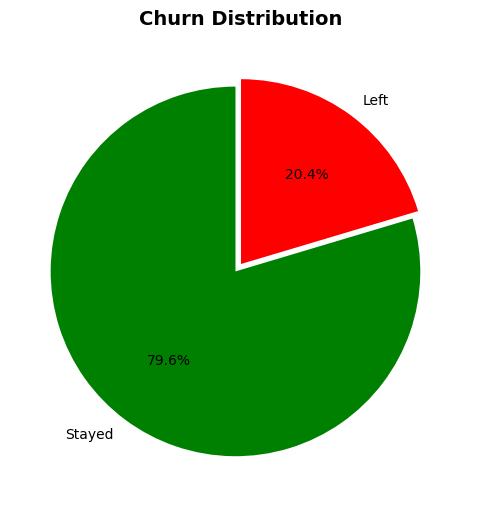

In [8]:
x = df["Exited"].value_counts()

plt.figure(figsize=(6,6))
plt.pie(x,
        labels=["Stayed", "Left"],
        autopct="%1.1f%%",
       colors=["green","red"],
        explode=(0.05, 0),
        startangle=90,
        )

plt.title("Churn Distribution", fontsize=14, fontweight="bold")
plt.show()

In [9]:
df.select_dtypes(include='number').columns

Index(['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts',
       'EstimatedSalary', 'Exited', 'Satisfaction Score', 'Point Earned'],
      dtype='object')

In [10]:
numeric_columns = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary', 'Point Earned', 'Satisfaction Score']

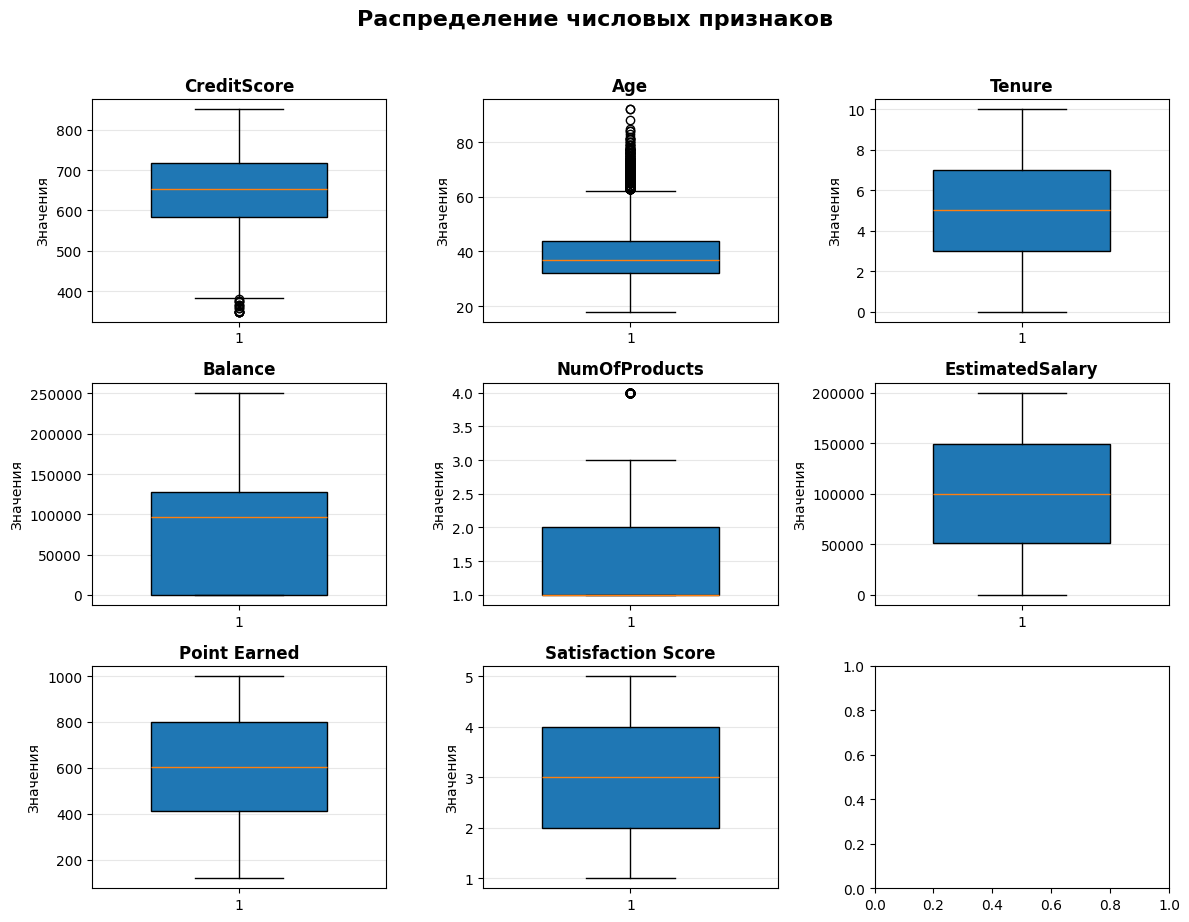

In [11]:
fig, axes = plt.subplots(3, 3, figsize=(12, 9))
axes = axes.flatten()


for idx, (col, ax) in enumerate(zip(numeric_columns, axes)):
    bp = ax.boxplot(df[col], patch_artist=True, widths=0.6)

    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.set_ylabel('Значения', fontsize=10)
    ax.grid(axis='y', alpha=0.3)


plt.suptitle('Распределение числовых признаков', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [12]:
df.describe(include=object).T

,count,unique,top,freq
Geography,10000,3,France,5014
Gender,10000,2,Male,5457
Card Type,10000,4,DIAMOND,2507


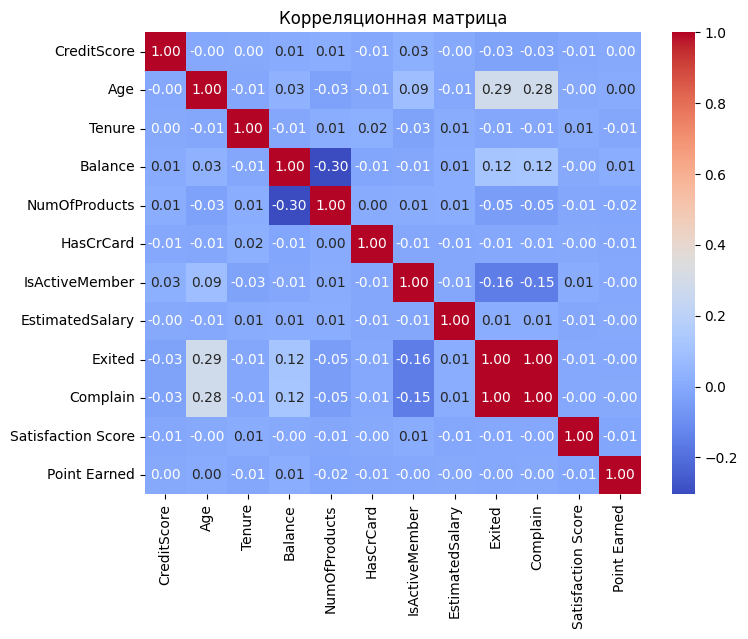

In [13]:
correlation_matrix = df.drop(['Geography', 'Gender', 'Card Type'], axis=1).corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Корреляционная матрица")
plt.show()

In [14]:
pd.crosstab(df['Complain'], df['Exited'], normalize='index')

Exited,0,1
Complain,,
False,0.999497,0.000503
True,0.004892,0.995108


In [15]:
df.drop(['Complain'], axis=1, inplace=True)

Complain практически полностью определяет target. Такая связь подозрительна. Если информация о жалобе появляется непосредственно при процессе ухода клиента или после момента, на который должен делаться прогноз, признак является target leakage, поэтому он исключён.

In [16]:
df.shape

(10000, 14)

In [17]:
duplicates = df.duplicated().sum()

print(f'DUPCLICATED ROWS {duplicates}')

DUPCLICATED ROWS 0


### Сводка по датасету

- Размер датасета - (10000, 14)
- Типы данных - int64, float64, object, bool
- Пропусков нет
- Дубликатов нет
- Распределение целевой переменной - сильный диcбаланс классов в пользу stayed
- Признаки не влияющие на предсказание - **RowNumber, CustomerId, Surname**	(поэтому были удалены). **Complain** удален из-за возникновения data leakage
- Категориальные признаки - **Geography, Gender, Card Type**.
- Значимых выбросов нет

### Подготовка к обучению

In [18]:
cat_columns = ['Geography', 'Gender', 'Card Type']
numeric_columns = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary', 'Point Earned', 'Satisfaction Score']

X = df.drop('Exited', axis=1)
y = df['Exited']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y) #Применяем stratify для сохранения пропорций классов

In [19]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_columns),
        ('cat', OneHotEncoder(), cat_columns),
    ], remainder='passthrough'
)

X_train_scaled = preprocessor.fit_transform(X_train)

In [20]:
def calculate_metrics(y_test, y_pred):
    accuracy = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)

    print(f'accuracy = {round(accuracy, 3)}')
    print(f'f1 = {round(f1, 3)}')
    print(f'recall = {round(recall, 3)}')
    print(f'precision = {round(precision, 3)}')

# Эксперименты

### Влияние гиперпараметров на LogisticRegression

In [21]:
# Базовая модель
skf = StratifiedKFold(n_splits=5)

model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)
predictions = model.predict(X_train_scaled)


pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(max_iter=1000, random_state=42))
])
scores = cross_val_score(pipeline, X_train, y_train, cv=skf, scoring='f1')

print(f'Train F1 {round(f1_score(y_train, predictions), 3)}')
print(f'CV F1 {round(scores.mean(), 3)}')

Train F1 0.311
CV F1 0.311


In [22]:
# Учитываем дисбаланс классов
model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)
predictions = model.predict(X_train_scaled)

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])
scores = cross_val_score(pipeline, X_train, y_train, cv=skf, scoring='f1')

print(f'Train F1 {round(f1_score(y_train, predictions), 3)}')
print(f'CV F1 {round(scores.mean(), 3)}')



Train F1 0.492
CV F1 0.488


In [23]:
# Пробуем изменить threshold
model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

custom_threshold = 0.3

def make_f1_with_threshold(threshold):
    def f1_threshold(estimator, X, y):
        proba = estimator.predict_proba(X)[:, 1]
        y_pred = (proba >= threshold).astype(int)
        return f1_score(y, y_pred)
    return f1_threshold

skf = StratifiedKFold(n_splits=5)

probs = model.predict_proba(X_train_scaled)[:, 1]
predictions = (probs >= custom_threshold).astype(int)

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])

scores = cross_val_score(pipeline, X_train, y_train, cv=skf, scoring=make_f1_with_threshold(custom_threshold))

print(f'Train F1 {round(f1_score(y_train, predictions), 3)}')
print(f'CV F1 {round(scores.mean(), 3)}')

Train F1 0.42
CV F1 0.418


In [24]:
custom_threshold = 0.45

probs = model.predict_proba(X_train_scaled)[:, 1]
predictions = (probs >= custom_threshold).astype(int)

scores = cross_val_score(
    pipeline, X_train, y_train,
    cv=skf,
    scoring=make_f1_with_threshold(custom_threshold)
)

print(f'Train F1 {round(f1_score(y_train, predictions), 3)}')
print(f'CV F1 {round(scores.mean(), 3)}')

Train F1 0.483
CV F1 0.479


Можно заменить, что изменение порога прямо влияет на метрики, чем ниже порог, тем больше объектов мы относим к положительному классу. Вследствие этого растет recall, но падает precision. (Растет FP, уменьшается FN)

### KNN

In [25]:
from sklearn import neighbors
#Изучение влияния k = [1, 3, 5, 10, 20, 50]

neighbors = [1, 3, 5, 10, 20, 50]
for k in neighbors:
    pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', KNeighborsClassifier(n_neighbors=k))
])
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_train)
    scores = cross_val_score(
    pipeline, X_train, y_train,
    cv=skf,
    scoring='f1'
    )
    print(f'k = {k}')
    print(f'Train F1 {round(f1_score(y_train, predictions), 3)}')
    print(f'CV F1 {round(scores.mean(), 3)}')


k = 1
Train F1 1.0
CV F1 0.433
k = 3
Train F1 0.695
CV F1 0.443
k = 5
Train F1 0.599
CV F1 0.438
k = 10
Train F1 0.462
CV F1 0.363
k = 20
Train F1 0.412
CV F1 0.348
k = 50
Train F1 0.32
CV F1 0.266


In [26]:
# Что будет если обучить KNN без предварительного StandardScale

# Scaled
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', KNeighborsClassifier(n_neighbors=5))
])

pipeline.fit(X_train, y_train)
predictions = pipeline.predict(X_train)

scores = cross_val_score(
    pipeline, X_train, y_train,
    cv=skf,
    scoring='f1'
    )

print(f'with Scaling CV F1 = {round(scores.mean(), 3)}')

# Without scaling
X_train_encoded = pd.get_dummies(X_train, columns=cat_columns, prefix=cat_columns)

model = KNeighborsClassifier(n_neighbors=5)
scores = cross_val_score(
    model, X_train_encoded, y_train,
    cv=skf,
    scoring='f1'
    )

print(f'Without Scaling CV F1 = {round(scores.mean(), 3)}')

with Scaling CV F1 = 0.438
Without Scaling CV F1 = 0.127


Масштабирование признаков сильно влияет на предсказания модели, т.к. признак с большим масштабом при расчете расстояния вносит больший вклад

### DecisionTree

In [27]:
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train_scaled, y_train)
predictions = model.predict(X_train_scaled)
train_predictions = model.predict(X_train_scaled)

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', DecisionTreeClassifier(random_state=42))
])

scores = cross_val_score(
    pipeline, X_train, y_train,
    cv=skf,
    scoring='f1'
)

print(f'Train f1 = {round(f1_score(y_train, train_predictions), 3)}')
print(f'CV f1 {round(scores.mean(), 3)}')

Train f1 = 1.0
CV f1 0.486


Можно заметить признаки переобучения

In [28]:
# Посмотрим на влияние max_depth
depth = [1, 2, 3, 5, 10, 20, None]
for d in depth:
    pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', DecisionTreeClassifier(max_depth=d, random_state=42))
    ])
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_train)
    scores = cross_val_score(
    pipeline, X_train, y_train,
    cv=skf,
    scoring='f1'
    )

    print(f'Max_depth = {d}')
    print(f'Train f1 = {round(f1_score(y_train, predictions), 3)}')
    print(f'CV f1 = {round(scores.mean(), 3)}')

Max_depth = 1
Train f1 = 0.0
CV f1 = 0.0
Max_depth = 2
Train f1 = 0.507
CV f1 = 0.503
Max_depth = 3
Train f1 = 0.39
CV f1 = 0.418
Max_depth = 5
Train f1 = 0.546
CV f1 = 0.521
Max_depth = 10
Train f1 = 0.751
CV f1 = 0.536
Max_depth = 20
Train f1 = 0.988
CV f1 = 0.485
Max_depth = None
Train f1 = 1.0
CV f1 = 0.486


In [29]:
# Визуализация небольшого дерева
model = DecisionTreeClassifier(max_depth=3, random_state=42)
model.fit(X_train_scaled, y_train)

feature_names= preprocessor.get_feature_names_out()
tree = export_text(model, feature_names=feature_names)

print(tree)

|--- num__Age <= 0.34
|   |--- num__NumOfProducts <= 1.67
|   |   |--- num__NumOfProducts <= -0.05
|   |   |   |--- class: 0
|   |   |--- num__NumOfProducts >  -0.05
|   |   |   |--- class: 0
|   |--- num__NumOfProducts >  1.67
|   |   |--- num__Balance <= -0.33
|   |   |   |--- class: 0
|   |   |--- num__Balance >  -0.33
|   |   |   |--- class: 1
|--- num__Age >  0.34
|   |--- remainder__IsActiveMember <= 0.50
|   |   |--- num__Age <= 1.10
|   |   |   |--- class: 0
|   |   |--- num__Age >  1.10
|   |   |   |--- class: 1
|   |--- remainder__IsActiveMember >  0.50
|   |   |--- num__NumOfProducts <= 1.67
|   |   |   |--- class: 0
|   |   |--- num__NumOfProducts >  1.67
|   |   |   |--- class: 1



### RandomForest

In [30]:
# Посмотрим на влияние n_estimators
n_estimators = [50, 100, 300, 500, 1000]


for n in n_estimators:
    pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(n_estimators=n, random_state=42))
    ])
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_train)

    scores = cross_val_score(
    pipeline, X_train, y_train,
    cv=skf,
    scoring='f1'
    )

    print(f'n_estimators = {n}')
    print(f'Train f1 = {round(f1_score(y_train, predictions), 3)}')
    print(f'CV F1 {round(scores.mean(), 3)}')

n_estimators = 50
Train f1 = 0.998
CV F1 0.544
n_estimators = 100
Train f1 = 1.0
CV F1 0.556
n_estimators = 300
Train f1 = 1.0
CV F1 0.566
n_estimators = 500
Train f1 = 1.0
CV F1 0.564
n_estimators = 1000
Train f1 = 1.0
CV F1 0.565


<Axes: xlabel='feature_names'>

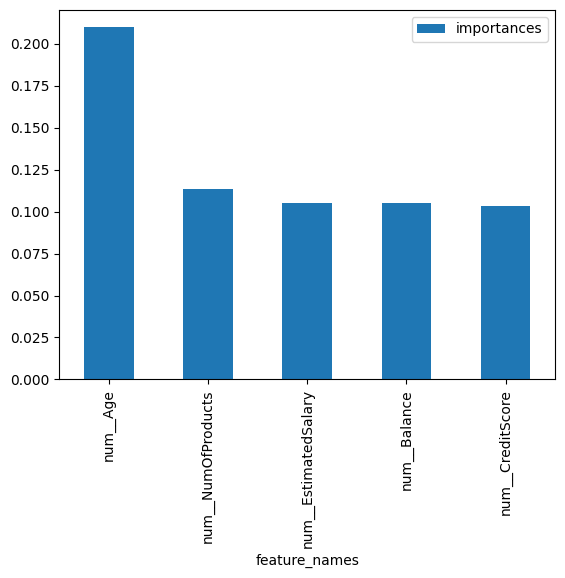

In [31]:
# Исследуем feature_importances_
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train_scaled, y_train)

importances = model.feature_importances_
feature_names = preprocessor.get_feature_names_out()

importances_df = pd.DataFrame({
    'feature_names': feature_names,
    'importances': importances
})

importances_df.sort_values(by='importances', ascending=False).head(5).plot.bar(x='feature_names', y='importances')

### SVM

In [32]:
model = SVC(kernel='linear')
model.fit(X_train_scaled, y_train)
predictions = model.predict(X_train_scaled)

print('linear')
calculate_metrics(y_train, predictions)

model = SVC(kernel='rbf')
model.fit(X_train_scaled, y_train)
predictions = model.predict(X_train_scaled)

print('rbf')
calculate_metrics(y_train, predictions)

linear
accuracy = 0.796
f1 = 0.0
recall = 0.0
precision = 0.0


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


rbf
accuracy = 0.871
f1 = 0.579
recall = 0.435
precision = 0.865


In [33]:
C = [0.01, 0.1, 1, 10, 100]
for c in C:
    pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', SVC(kernel='rbf', C=c, random_state=42))
    ])
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_train)
    scores = cross_val_score(
    pipeline, X_train, y_train,
    cv=skf,
    scoring='f1'
    )

    print(f'C = {c}')
    print(f'Train f1 = {round(f1_score(y_train, predictions), 3)}')
    print(f'CV f1 = {round(scores.mean(), 3)}')

C = 0.01
Train f1 = 0.0
CV f1 = 0.0
C = 0.1
Train f1 = 0.21
CV f1 = 0.163
C = 1
Train f1 = 0.579
CV f1 = 0.524
C = 10
Train f1 = 0.77
CV f1 = 0.548
C = 100
Train f1 = 0.963
CV f1 = 0.506


In [34]:
gamma = [0.001, 0.01, 0.1, 1, 10]
for g in gamma:
    pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', SVC(kernel='rbf', C=10, gamma=g, random_state=42))
    ])
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_train)
    scores = cross_val_score(
    pipeline, X_train, y_train,
    cv=skf,
    scoring='f1'
    )

    print(f'gamma = {g}')
    print(f'Train f1 = {round(f1_score(y_train, predictions), 3)}')
    print(f'CV f1 = {round(scores.mean(), 3)}')

gamma = 0.001
Train f1 = 0.0
CV f1 = 0.0
gamma = 0.01
Train f1 = 0.488
CV f1 = 0.468
gamma = 0.1
Train f1 = 0.806
CV f1 = 0.546
gamma = 1
Train f1 = 1.0
CV f1 = 0.039
gamma = 10
Train f1 = 1.0
CV f1 = 0.0


In [35]:
# Scaled
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', SVC(random_state=42))
    ])

scores = cross_val_score(
    pipeline, X_train, y_train,
    cv=skf,
    scoring='f1'
    )

print(f'with Scaling CV F1 = {round(scores.mean(), 3)}')

# Without scaling
X_train_encoded = pd.get_dummies(X_train, columns=cat_columns, prefix=cat_columns)

model = SVC(random_state=42)

scores = cross_val_score(
    model, X_train_encoded, y_train,
    cv=skf,
    scoring='f1'
    )

print(f'without Scaling CV F1 = {round(scores.mean(), 3)}')

with Scaling CV F1 = 0.524
without Scaling CV F1 = 0.0


# Cross-validation

In [36]:
skf = StratifiedKFold(n_splits=5)

models = {
    "LogisticRegression": Pipeline([
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)),
    ]),
    "KNeighbors": Pipeline([
        ("preprocessor", preprocessor),
        ("model", KNeighborsClassifier()),
    ]),
    "SVC": Pipeline([
        ("preprocessor", preprocessor),
        ("model", SVC(class_weight='balanced', kernel="rbf", random_state=42)),
    ]),
    "DecisionTree": Pipeline([
        ("preprocessor", preprocessor),
        ("model", DecisionTreeClassifier(class_weight='balanced', random_state=42)),
    ]),
    "RandomForest": Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(class_weight='balanced', random_state=42)),
    ]),
}

print(f'{"Model":<22} {"CV F1 mean":>12} {"CV F1 std":>12}')
print('-' * 48)

for name, pipeline in models.items():
    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=skf,
        scoring='f1',
    )
    print(f'{name:<22} {scores.mean():>12.4f} {scores.std():>12.4f}')

Model                    CV F1 mean    CV F1 std
------------------------------------------------
LogisticRegression           0.4882       0.0064
KNeighbors                   0.4377       0.0130
SVC                          0.5894       0.0062
DecisionTree                 0.4765       0.0133
RandomForest                 0.5222       0.0265


# Подбор гиперпараметров (для RF и LR)

In [37]:
param_grid = {
    'model__n_estimators': [2, 3, 5, 10, 20, 50, 100],
    'model__max_depth': [2, 3, 5, 10, 20, 50, None],
    'model__min_samples_split': [2, 3, 5, 7, 10],
}

pipe = Pipeline([
    ('preproccesor', preprocessor),
    ('model', RandomForestClassifier(class_weight='balanced', random_state=42))
])

grid_search = GridSearchCV(
    estimator=pipe,
    param_grid=param_grid,
    cv=skf,
    scoring='f1',
    n_jobs=-1,
    verbose=0
)

grid_search.fit(X_train, y_train)

print("Лучшие параметры:", grid_search.best_params_)
print("Лучшая оценка по CV:", grid_search.best_score_)

Лучшие параметры: {'model__max_depth': 10, 'model__min_samples_split': 10, 'model__n_estimators': 100}
Лучшая оценка по CV: 0.6172469690697573


In [38]:
param_grid = [
    {
    'model__C': [0.001, 0.01, 0.1, 1, 10, 100],
    'model__penalty': ['elasticnet'],
    'model__solver': ['saga'],
    'model__l1_ratio': [0.1, 0.5, 0.9]
    },
    {
    'model__C': [0.001, 0.01, 0.1, 1, 10, 100],
    'model__penalty': ['l1', 'l2'],
    'model__solver': ['liblinear']
    },
    ]

pipe = Pipeline([
    ('preproccesor', preprocessor),
    ('model', LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000))
])

grid_search = GridSearchCV(
    estimator=pipe,
    param_grid=param_grid,
    cv=skf,
    scoring='f1',
    n_jobs=-1,
    verbose=0
)

grid_search.fit(X_train, y_train)

print("Лучшие параметры:", grid_search.best_params_)
print("Лучшая оценка по CV:", grid_search.best_score_)

Лучшие параметры: {'model__C': 0.01, 'model__l1_ratio': 0.9, 'model__penalty': 'elasticnet', 'model__solver': 'saga'}
Лучшая оценка по CV: 0.5010296445302258


# Выбор итоговой модели

In [39]:
model = RandomForestClassifier(max_depth=10, min_samples_split=10, n_estimators=100, class_weight='balanced', random_state=42)

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', model)
    ])

pipeline.fit(X_train, y_train)
predictions = pipeline.predict(X_test)
print('RandomForest')
print(f'F1 = {f1_score(y_test, predictions)}')
print(f'Precision = {precision_score(y_test, predictions)}')
print(f'Recall = {recall_score(y_test, predictions)}')
print(f'ROC-AUC = {roc_auc_score(y_test, predictions)}')
print(f'PR-AUC = {average_precision_score(y_test, pipeline.predict_proba(X_test)[:, 1:])}')

print(f' Confusion matrix: \n{confusion_matrix(y_test, predictions)}')



RandomForest
F1 = 0.6251415628539071
Precision = 0.5810526315789474
Recall = 0.6764705882352942
ROC-AUC = 0.7757352941176471
PR-AUC = 0.6964897961345228
 Confusion matrix: 
[[1393  199]
 [ 132  276]]


На основании cross-validation в качестве итоговой модели выбран Random Forest с CV F1 ≈ 0.617. После фиксации модели она была оценена на отложенной test-выборке и получила F1 = 0.625.

# Визуализация границ принятия решений

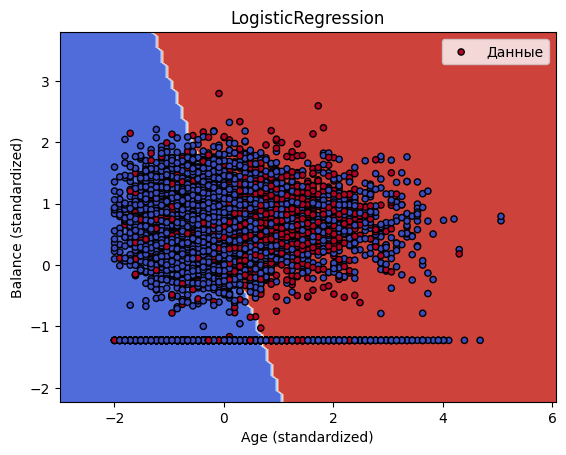

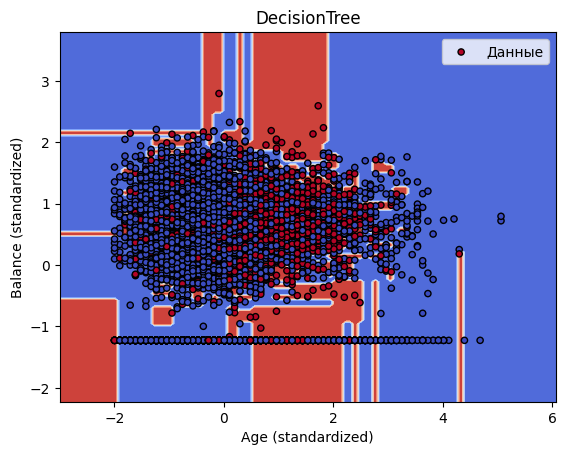

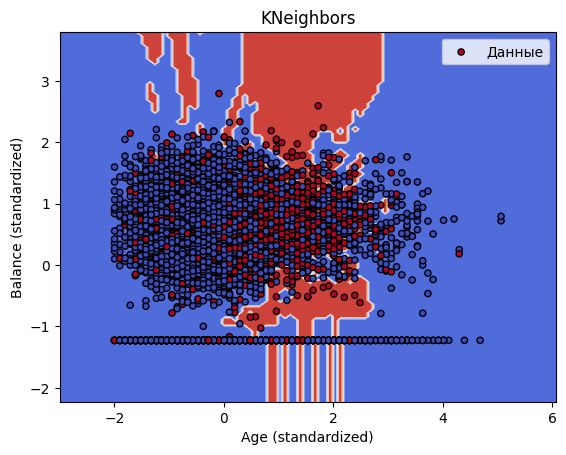

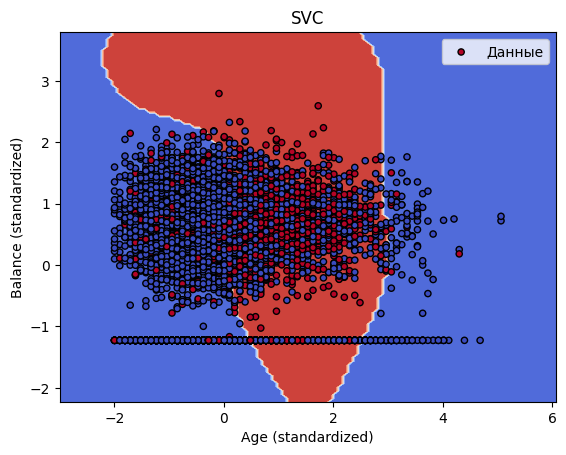

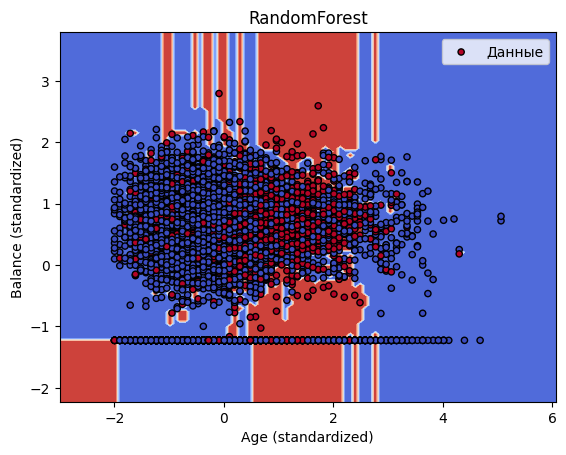

In [40]:
X_db = df[['Age', 'Balance']]
y_db = df['Exited']

scaler = StandardScaler()
X_db_scaled = scaler.fit_transform(X_db)

models = {
    "LogisticRegression": LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000),
    "DecisionTree": DecisionTreeClassifier(class_weight='balanced', random_state=42),
    "KNeighbors": KNeighborsClassifier(),
    "SVC": SVC(class_weight='balanced', kernel="rbf", probability=False, random_state=42),
    "RandomForest": RandomForestClassifier(class_weight='balanced', random_state=42)
}

for name, model in models.items():
    model.fit(X_db_scaled, y_db)

    disp = DecisionBoundaryDisplay.from_estimator(
        model, X_db_scaled,
        response_method="predict",
        cmap="coolwarm",
        xlabel="Age (standardized)",
        ylabel="Balance (standardized)"\
    )

    disp.ax_.scatter(
        X_db_scaled[:, 0], X_db_scaled[:, 1],
        c=y_db,
        edgecolors='k',
        cmap="coolwarm",
        s=20,
        label="Данные"
    )
    disp.ax_.legend()

    disp.ax_.set_title(name)
    plt.show()